<a href="https://colab.research.google.com/github/AadiVM2403/AML-Classwork/blob/main/AML_Lab_Assignment_(261100610025).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

               Model        MSE      MAE  R2 Score
0  Linear Regression  2900.1936  42.7941    0.4526
1   Ridge Regression  2892.0146  42.8120    0.4541
2   Lasso Regression  2824.5681  42.8030    0.4669


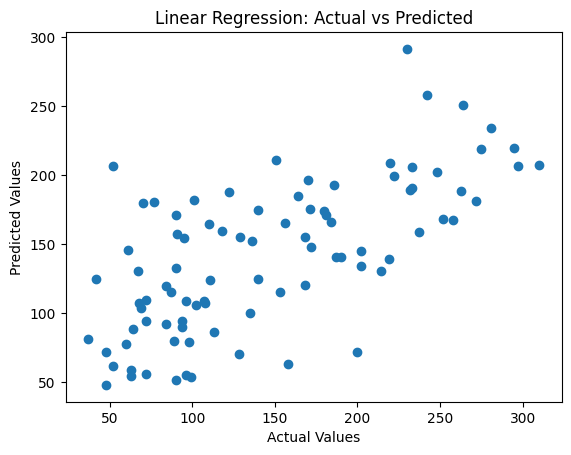

In [1]:
# AML Lab Assignment
# Aaditya V Menon
# 261100610025



# Experiment 1(a): Linear, Ridge and Lasso Regression

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Load dataset
data = load_diabetes()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Define models
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": make_pipeline(
        StandardScaler(), Ridge(alpha=1.0)
    ),
    "Lasso Regression": make_pipeline(
        StandardScaler(), Lasso(alpha=1.0, max_iter=10000)
    )
}

results = []

# Train and evaluate
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MSE": mean_squared_error(y_test, predictions),
        "MAE": mean_absolute_error(y_test, predictions),
        "R2 Score": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)
print(results_df.round(4))

# Plot actual vs predicted for Linear Regression
model = models["Linear Regression"]
predictions = model.predict(X_test)

plt.scatter(y_test, predictions)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Linear Regression: Actual vs Predicted")
plt.show()


Criterion: Gini
Accuracy: 0.9666666666666667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


Criterion: Entropy
Accuracy: 0.9666666666666667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



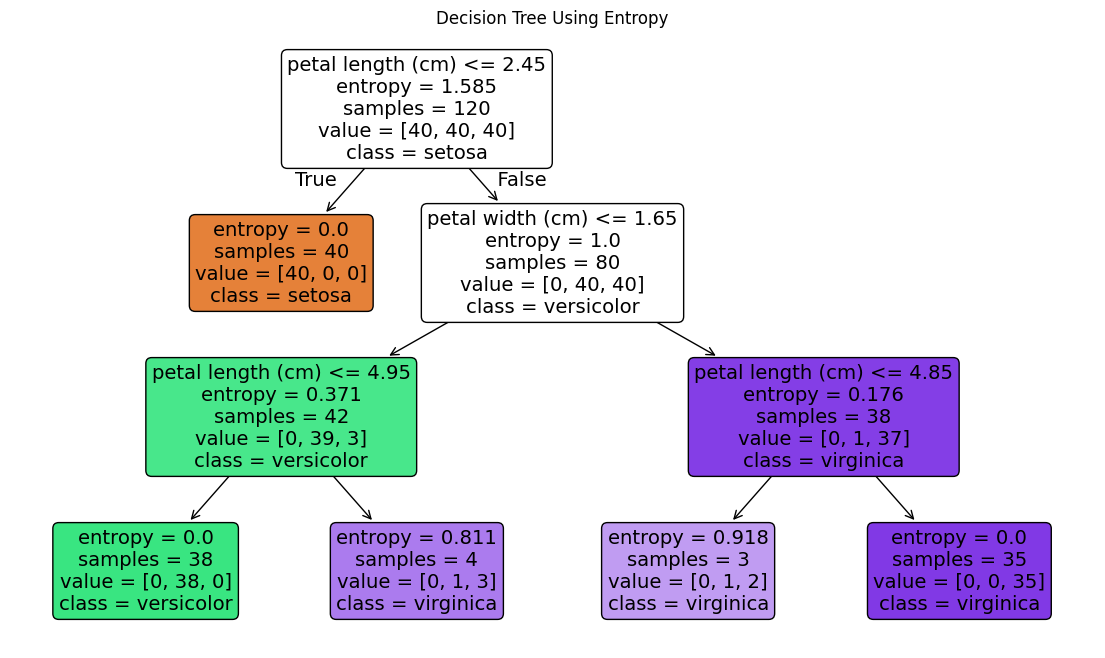

In [2]:
# Experiment 1(b): Decision Tree Classification

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

data = load_iris()
X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    "Gini": DecisionTreeClassifier(
        criterion="gini", random_state=42, max_depth=3
    ),
    "Entropy": DecisionTreeClassifier(
        criterion="entropy", random_state=42, max_depth=3
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    print("\nCriterion:", name)
    print("Accuracy:", accuracy_score(y_test, predictions))
    print(classification_report(
        y_test, predictions, target_names=data.target_names
    ))

# Visualize the entropy-based tree
tree_model = models["Entropy"]

plt.figure(figsize=(14, 8))
plot_tree(
    tree_model,
    feature_names=data.feature_names,
    class_names=data.target_names,
    filled=True,
    rounded=True
)
plt.title("Decision Tree Using Entropy")
plt.show()


Model: L2 (Ridge) Logistic
Accuracy: 0.9824561403508771
Confusion Matrix:
 [[41  1]
 [ 1 71]]
ROC-AUC: 0.9953703703703703
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


Model: L1 (Lasso) Logistic
Accuracy: 0.9912280701754386
Confusion Matrix:
 [[41  1]
 [ 0 72]]
ROC-AUC: 0.9966931216931216
              precision    recall  f1-score   support

           0       1.00      0.98      0.99        42
           1       0.99      1.00      0.99        72

    accuracy                           0.99       114
   macro avg       0.99      0.99      0.99       114
weighted avg       0.99      0.99      0.99       114



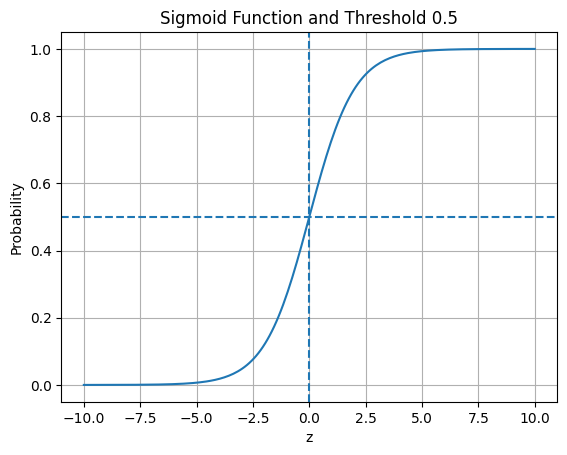

In [3]:
# Experiment 1(c): Logistic Regression

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import classification_report, roc_auc_score

data = load_breast_cancer()
X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    "L2 (Ridge) Logistic": make_pipeline(
        StandardScaler(),
        LogisticRegression(penalty="l2", C=1.0, max_iter=5000)
    ),
    "L1 (Lasso) Logistic": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty="l1", solver="liblinear",
            C=1.0, max_iter=5000
        )
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    print("\nModel:", name)
    print("Accuracy:", accuracy_score(y_test, predictions))
    print("Confusion Matrix:\n", confusion_matrix(y_test, predictions))
    print("ROC-AUC:", roc_auc_score(y_test, probabilities))
    print(classification_report(y_test, predictions))

# Sigmoid function
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

z = np.linspace(-10, 10, 200)
plt.plot(z, sigmoid(z))
plt.axhline(0.5, linestyle="--")
plt.axvline(0, linestyle="--")
plt.xlabel("z")
plt.ylabel("Probability")
plt.title("Sigmoid Function and Threshold 0.5")
plt.grid(True)
plt.show()

K =  1, Accuracy = 0.9667
K =  2, Accuracy = 0.9333
K =  3, Accuracy = 0.9333
K =  4, Accuracy = 0.9333
K =  5, Accuracy = 0.9333
K =  6, Accuracy = 0.9333
K =  7, Accuracy = 0.9667
K =  8, Accuracy = 0.9333
K =  9, Accuracy = 0.9667
K = 10, Accuracy = 0.9667
K = 11, Accuracy = 0.9667
K = 12, Accuracy = 0.9667
K = 13, Accuracy = 0.9667
K = 14, Accuracy = 0.9667
K = 15, Accuracy = 0.9667

Best K on this test split: 1

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.91      1.00      0.95        10
           2       1.00      0.90      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



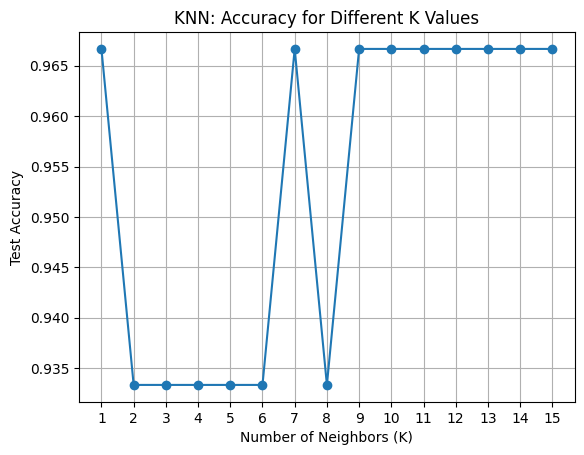

In [4]:
# Experiment 1(d): KNN Classification

import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

data = load_iris()
X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scores = []

# Test different values of K
for k in range(1, 16):
    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    accuracy = accuracy_score(y_test, predictions)
    scores.append(accuracy)

    print(f"K = {k:2d}, Accuracy = {accuracy:.4f}")

best_k = range(1, 16)[scores.index(max(scores))]
print("\nBest K on this test split:", best_k)

# Train final model
final_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=best_k)
)
final_model.fit(X_train, y_train)

predictions = final_model.predict(X_test)
print("\nClassification Report:")
print(classification_report(y_test, predictions))

plt.plot(range(1, 16), scores, marker="o")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Test Accuracy")
plt.title("KNN: Accuracy for Different K Values")
plt.xticks(range(1, 16))
plt.grid(True)
plt.show()

In [5]:
# Experiment 1(e): Gaussian Naive Bayes

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import classification_report

data = load_iris()
X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = GaussianNB()
model.fit(X_train, y_train)

predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)

print("Accuracy:", accuracy_score(y_test, predictions))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predictions))

print("\nClassification Report:")
print(classification_report(
    y_test, predictions, target_names=data.target_names
))

print("\nProbabilities for first 5 test samples:")
print(probabilities[:5])

Accuracy: 0.9666666666666667

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


Probabilities for first 5 test samples:
[[1.00000000e+000 2.10423610e-020 1.24046690e-025]
 [8.47878473e-143 8.77457913e-002 9.12254209e-001]
 [2.60594992e-036 9.99999490e-001 5.10180517e-007]
 [1.34650506e-036 9.99999567e-001 4.32500853e-007]
 [1.00000000e+000 6.60692071e-021 6.79224134e-026]]


Euclidean distance: 1.1762186834130146
Cosine similarity: 0.8658625731909563

K-Means Silhouette Score: 0.45994823920518635


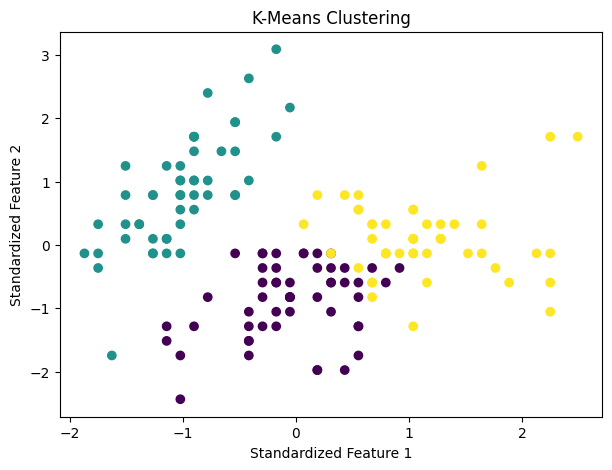

Single linkage silhouette score: 0.5046
Complete linkage silhouette score: 0.4496
Average linkage silhouette score: 0.4803
Ward linkage silhouette score: 0.4467


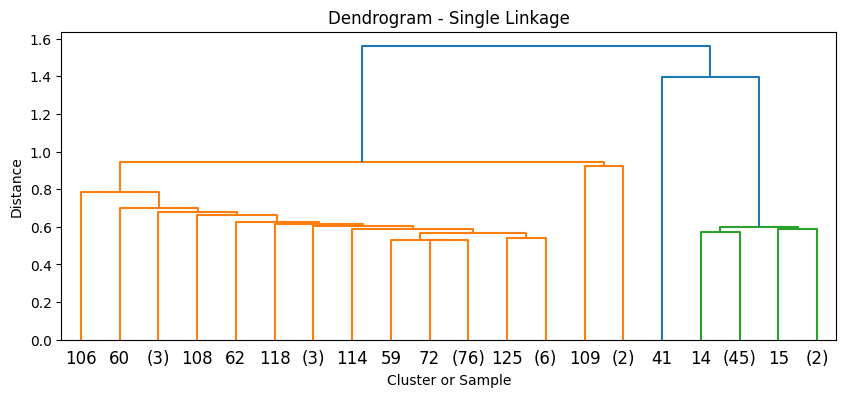

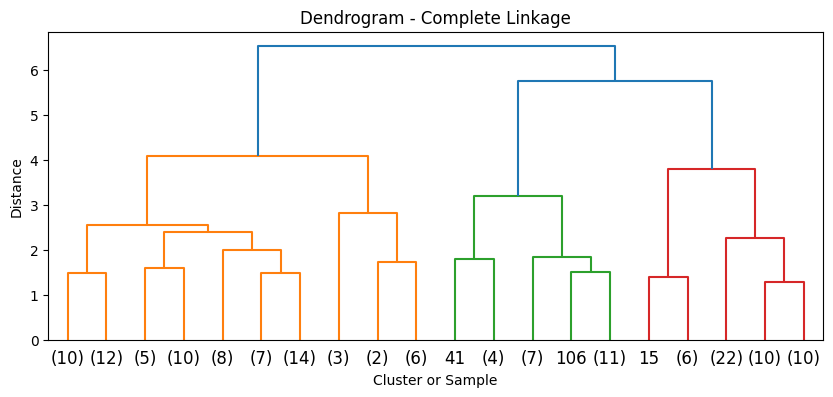

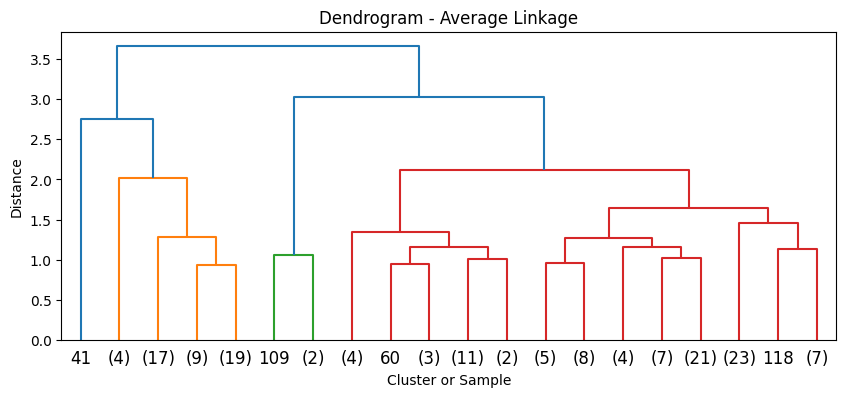

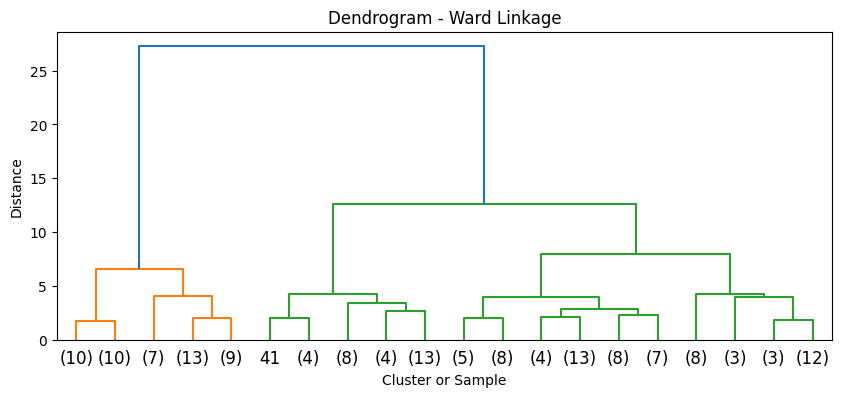

In [6]:
# Experiment 2(a): K-Means and Hierarchical Clustering

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import euclidean, cosine

data = load_iris()
X = StandardScaler().fit_transform(data.data)

# 1. Calculate distances and similarities
print("Euclidean distance:", euclidean(X[0], X[1]))
print("Cosine similarity:", 1 - cosine(X[0], X[1]))

# 2. K-Means clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X)

print("\nK-Means Silhouette Score:",
      silhouette_score(X, kmeans_labels))

# Visualize K-Means clusters using two features
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=kmeans_labels, cmap="viridis")
plt.xlabel("Standardized Feature 1")
plt.ylabel("Standardized Feature 2")
plt.title("K-Means Clustering")
plt.show()

# 3. Hierarchical clustering with different linkage methods
for method in ["single", "complete", "average", "ward"]:
    model = AgglomerativeClustering(
        n_clusters=3, linkage=method
    )
    labels = model.fit_predict(X)

    print(f"{method.capitalize()} linkage silhouette score:",
          round(silhouette_score(X, labels), 4))

# 4. Construct dendrograms
for method in ["single", "complete", "average", "ward"]:
    Z = linkage(X, method=method)

    plt.figure(figsize=(10, 4))
    dendrogram(Z, truncate_mode="lastp", p=20)
    plt.title(f"Dendrogram - {method.capitalize()} Linkage")
    plt.xlabel("Cluster or Sample")
    plt.ylabel("Distance")
    plt.show()

In [7]:
# Experiment 2(b): Ensemble Methods

import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics import classification_report

data = load_breast_cancer()
X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),

    "Bagging": BaggingClassifier(
        estimator=DecisionTreeClassifier(),
        n_estimators=100,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),

    "AdaBoost": AdaBoostClassifier(
        n_estimators=100, random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, random_state=42
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

    print(f"\n{name}")
    print(classification_report(y_test, predictions))

print("\nModel Comparison:")
print(pd.DataFrame(results).round(4).to_string(index=False))


Decision Tree
              precision    recall  f1-score   support

           0       0.85      0.93      0.89        42
           1       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114


Bagging
              precision    recall  f1-score   support

           0       0.93      0.90      0.92        42
           1       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114


Random Forest
              precision    recall  f1-score   support

           0       0.95      0.93      0.94        42
           1       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96  

Cluster labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 0 2 0
 0 0 0 2 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]

Silhouette Score: 0.37416491866541235

BIC: 801.5458721551512
AIC: 669.0779192149159

Membership probabilities for first 5 samples:
[[0. 1. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 1. 0.]]


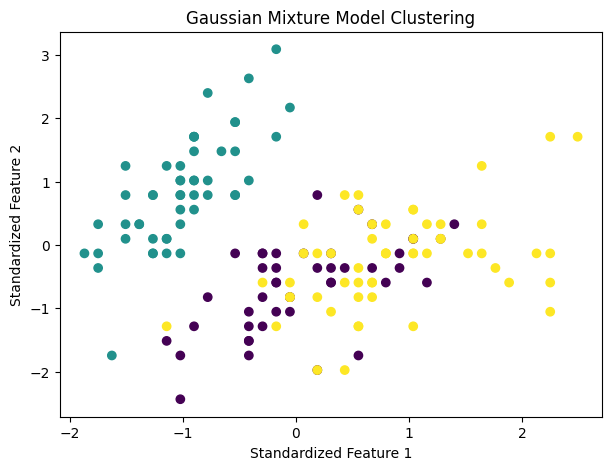

In [8]:
# Experiment 2(c): Gaussian Mixture Model

import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

data = load_iris()
X = StandardScaler().fit_transform(data.data)

# Fit GMM
gmm = GaussianMixture(
    n_components=3, random_state=42, n_init=5
)
gmm.fit(X)

labels = gmm.predict(X)
probabilities = gmm.predict_proba(X)

print("Cluster labels:")
print(labels)

print("\nSilhouette Score:",
      silhouette_score(X, labels))

print("\nBIC:", gmm.bic(X))
print("AIC:", gmm.aic(X))

print("\nMembership probabilities for first 5 samples:")
print(probabilities[:5].round(4))

# Visualize clusters using the first two features
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis")
plt.xlabel("Standardized Feature 1")
plt.ylabel("Standardized Feature 2")
plt.title("Gaussian Mixture Model Clustering")
plt.show()

Original shape: (150, 4)
Reduced shape: (150, 2)

Explained variance ratio:
[0.72962445 0.22850762]
Total variance retained: 0.9581320720000166


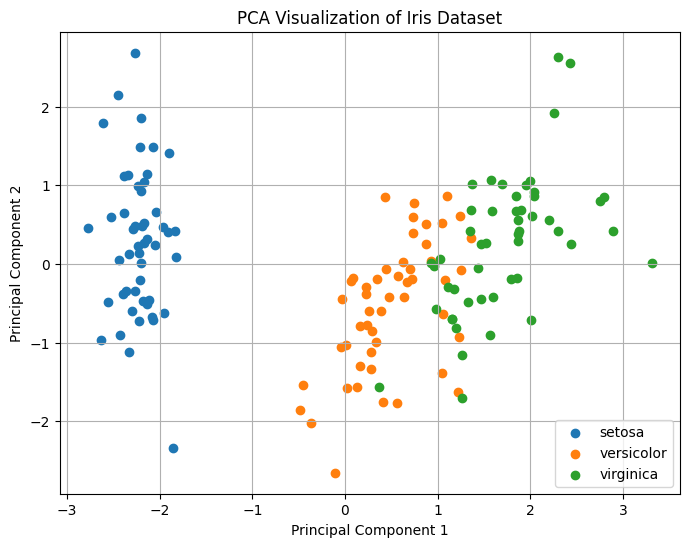


PCA component loadings:
[[ 0.52106591 -0.26934744  0.5804131   0.56485654]
 [ 0.37741762  0.92329566  0.02449161  0.06694199]]


In [9]:
# Experiment 2(d): Principal Component Analysis

import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

data = load_iris()
X = data.data
y = data.target

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Reduce 4 dimensions to 2
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Original shape:", X.shape)
print("Reduced shape:", X_pca.shape)

print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_)

print("Total variance retained:",
      pca.explained_variance_ratio_.sum())

# Visualize principal components
plt.figure(figsize=(8, 6))

for class_id, class_name in enumerate(data.target_names):
    plt.scatter(
        X_pca[y == class_id, 0],
        X_pca[y == class_id, 1],
        label=class_name
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Iris Dataset")
plt.legend()
plt.grid(True)
plt.show()

# Display component loadings
print("\nPCA component loadings:")
print(pca.components_)

                     Accuracy  Precision  Recall  F1 Score  ROC-AUC
Model                                                              
Decision Tree          0.9123     0.9559  0.9028    0.9286   0.9157
Logistic Regression    0.9825     0.9861  0.9861    0.9861   0.9954
KNN                    0.9561     0.9589  0.9722    0.9655   0.9788
Naive Bayes            0.9386     0.9452  0.9583    0.9517   0.9878
Random Forest          0.9561     0.9589  0.9722    0.9655   0.9937
Gradient Boosting      0.9561     0.9467  0.9861    0.9660   0.9907


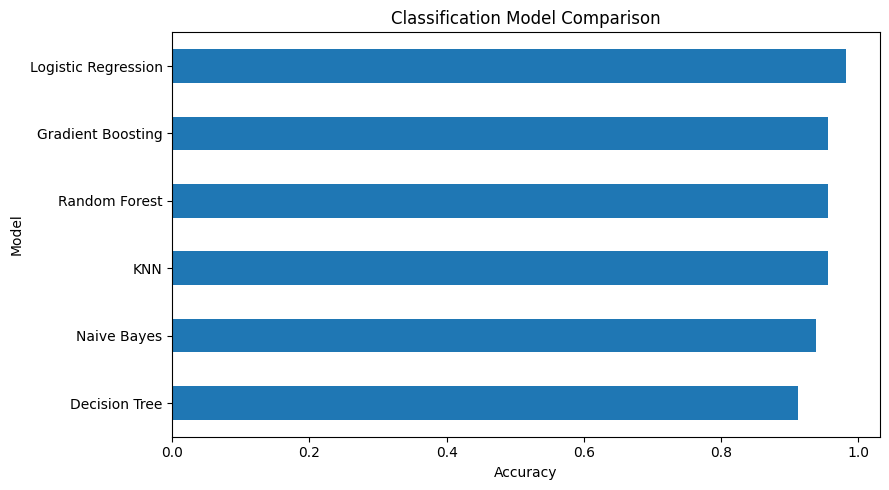

In [10]:
# Experiment 3(A): Classification Performance Comparison

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score, roc_auc_score

data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),

    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=5000)
    ),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "Naive Bayes": GaussianNB(),

    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(X_test)[:, 1]
    else:
        probabilities = None

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results).set_index("Model")
print(results_df.round(4))

# Compare model accuracy
results_df["Accuracy"].sort_values().plot(
    kind="barh", figsize=(9, 5)
)
plt.xlabel("Accuracy")
plt.title("Classification Model Comparison")
plt.tight_layout()
plt.show()

                         MSE     RMSE      MAE  R2 Score
Model                                                   
Linear Regression  2900.1936  53.8534  42.7941    0.4526
Ridge Regression   2892.0146  53.7775  42.8120    0.4541
Lasso Regression   2824.5681  53.1467  42.8030    0.4669


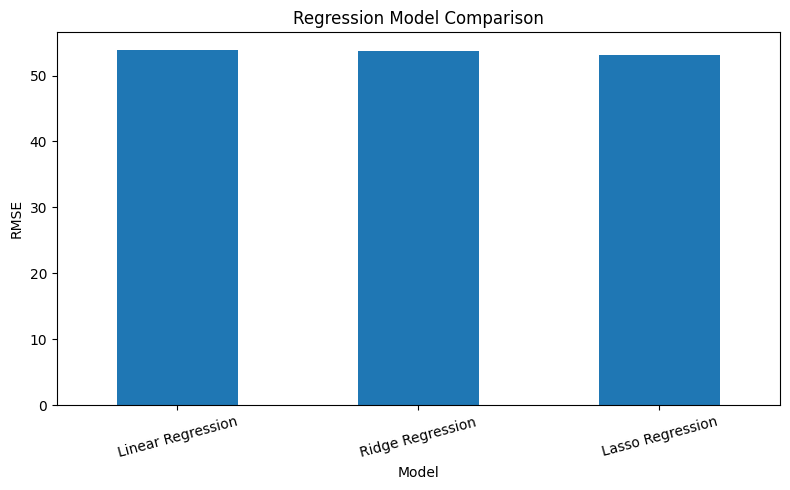

In [11]:
# Experiment 3(B): Regression Performance Comparison

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.metrics import r2_score

data = load_diabetes()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": make_pipeline(
        StandardScaler(), Ridge(alpha=1.0)
    ),

    "Lasso Regression": make_pipeline(
        StandardScaler(), Lasso(alpha=1.0, max_iter=10000)
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MSE": mean_squared_error(y_test, predictions),
        "RMSE": mean_squared_error(y_test, predictions) ** 0.5,
        "MAE": mean_absolute_error(y_test, predictions),
        "R2 Score": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results).set_index("Model")
print(results_df.round(4))

results_df["RMSE"].plot(kind="bar", figsize=(8, 5))
plt.ylabel("RMSE")
plt.title("Regression Model Comparison")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

              Silhouette Score  Davies-Bouldin Index  Calinski-Harabasz Score
Model                                                                        
K-Means                 0.4599                0.8336                 241.9044
Hierarchical            0.4467                0.8035                 222.7192
GMM                     0.3742                1.0809                 187.7745


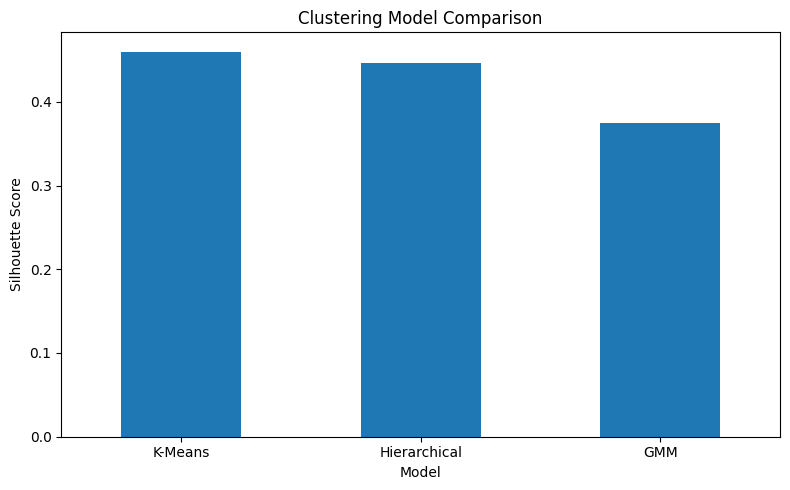

In [12]:
# Experiment 3(C): Clustering Performance Comparison

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score
from sklearn.metrics import calinski_harabasz_score

data = load_iris()
X = StandardScaler().fit_transform(data.data)

models = {
    "K-Means": KMeans(
        n_clusters=3, random_state=42, n_init=10
    ),

    "Hierarchical": AgglomerativeClustering(
        n_clusters=3, linkage="ward"
    ),

    "GMM": GaussianMixture(
        n_components=3, random_state=42, n_init=5
    )
}

results = []

for name, model in models.items():
    if name == "GMM":
        labels = model.fit_predict(X)
    else:
        labels = model.fit_predict(X)

    results.append({
        "Model": name,
        "Silhouette Score": silhouette_score(X, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X, labels),
        "Calinski-Harabasz Score": calinski_harabasz_score(X, labels)
    })

results_df = pd.DataFrame(results).set_index("Model")
print(results_df.round(4))

results_df["Silhouette Score"].plot(
    kind="bar", figsize=(8, 5)
)
plt.ylabel("Silhouette Score")
plt.title("Clustering Model Comparison")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()